# Streamgraph

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

A stacked area chart laid out around a central, wiggling baseline instead of zero. It gives an organic, flowing picture of how many categories rise and fall over time.

## When to use

- Show the ebb and flow of many categories over time (music genres, topics, species)
- Engaging, editorial graphics where overall patterns matter more than exact values

## Avoid when

- Precise values or totals must be read (there is no fixed baseline)
- Analytical or dashboard contexts
- There are few time points

## Alternatives

- Stacked area chart
- Small multiples
- Heatmap

## Example

Weekly listening share of six music genres across a year.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
weeks = np.arange(52)
genres = ["Pop", "Rock", "Hip-hop", "Electronic", "Jazz", "Classical"]
def bump(center, width, height):
    return height * np.exp(-((weeks - center) / width) ** 2)
df = pd.DataFrame({g: bump(rng.uniform(5, 47), rng.uniform(6, 14), rng.uniform(20, 60))
                   + rng.uniform(5, 15) for g in genres}, index=weeks)
df.head()

,Pop,Rock,Hip-hop,Electronic,Jazz,Classical
0,14.234561,6.236423,10.415002,18.722420,7.915236,13.947980
1,15.553709,6.310594,10.415227,21.647720,8.234183,14.009894
2,16.995351,6.439475,10.415592,25.020871,8.631717,14.094966
3,18.545954,6.655621,10.416173,28.733798,9.120822,14.210480
4,20.186054,7.005372,10.417087,32.616073,9.714739,14.365472


### Plot

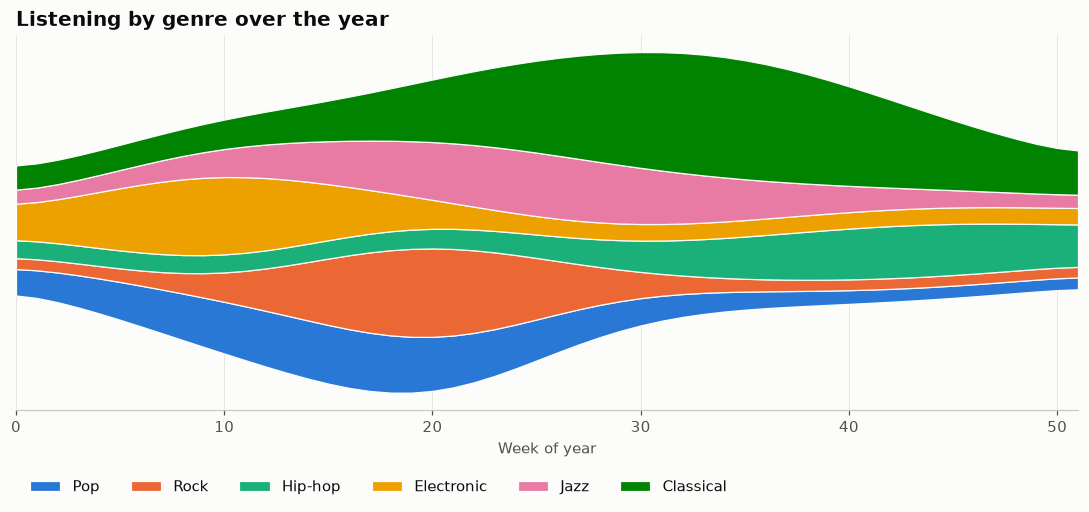

In [3]:
from scipy.ndimage import gaussian_filter1d
smooth = df.apply(lambda s: gaussian_filter1d(s, 1.5))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.stackplot(smooth.index, smooth.T.values, baseline="wiggle", labels=smooth.columns,
             colors=PALETTE[:6], edgecolor="#fcfcfb", linewidth=0.8)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Week of year")
ax.set_xlim(0, 51)
ax.set_title("Listening by genre over the year")
ax.legend(loc="upper left", ncol=6, bbox_to_anchor=(0, -0.15))
fig.tight_layout()
plt.show()

## How to read it

Band thickness at any week is that genre's listening volume. The vertical position has no meaning.

---
Standalone script: [`streamgraph.py`](streamgraph.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)